<a href="https://colab.research.google.com/github/Dathu03184/DSA0302-NLP/blob/main/Assignments/Assignment%2002/Implementation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 1: Counting Words and Building the Vocabulary

Total Tokens: 40
Vocabulary Size: 30

Word Frequencies:
to : 4
bus : 3
two : 2
i : 2
chennai : 2
book : 2
is : 2
tickets : 1
vellore : 1
need : 1
a : 1
from : 1
madurai : 1
can : 1
seats : 1
what : 1
the : 1
return : 1
fare : 1
leaves : 1
at : 1
6:30 : 1
please : 1
one : 1
ticket : 1
salem : 1
sleeper : 1
available : 1
train : 1
timing : 1

Vocabulary Table:
         Word  Frequency
0         two          2
1     tickets          1
2          to          4
3     vellore          1
4           i          2
5        need          1
6           a          1
7         bus          3
8        from          1
9     chennai          2
10    madurai          1
11        can          1
12       book          2
13      seats          1
14       what          1
15         is          2
16        the          1
17     return          1
18       fare          1
19     leaves          1
20         at          1
21       6:30          1
22     please          1
23        one          1
24     ticket 

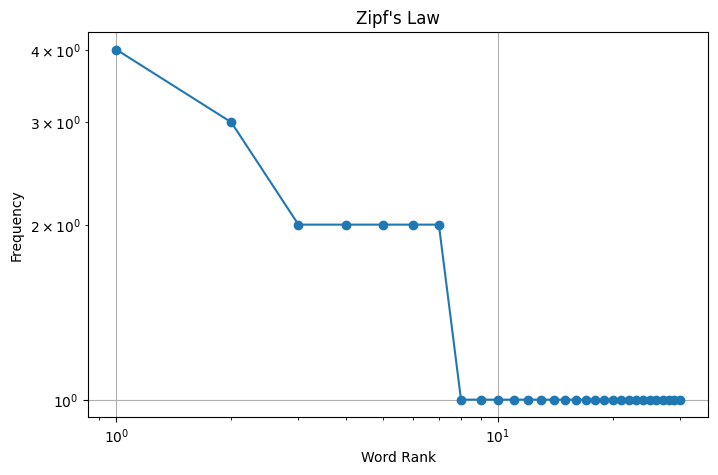

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Sample transport enquiry dataset
sentences = [
    "two tickets to vellore",
    "i need a bus from chennai to madurai",
    "can i book two seats",
    "what is the return fare",
    "bus leaves at 6:30",
    "please book one ticket to salem",
    "is sleeper bus available",
    "train timing to chennai"
]

# Tokenization
tokens = []

for sentence in sentences:
    words = re.findall(
        r"\d{1,2}:\d{2}|[a-z]+|[0-9]+",
        sentence.lower()
    )
    tokens.extend(words)

# Count words
word_counts = Counter(tokens)

# Display vocabulary
print("Total Tokens:", len(tokens))
print("Vocabulary Size:", len(word_counts))

print("\nWord Frequencies:")
for word, count in word_counts.most_common():
    print(word, ":", count)

# Create DataFrame
df = pd.DataFrame(
    word_counts.items(),
    columns=["Word", "Frequency"]
)

print("\nVocabulary Table:")
print(df)

# Zipf's Law
frequencies = sorted(word_counts.values(), reverse=True)
ranks = range(1, len(frequencies) + 1)

plt.figure(figsize=(8, 5))
plt.loglog(ranks, frequencies, marker='o')
plt.xlabel("Word Rank")
plt.ylabel("Frequency")
plt.title("Zipf's Law")
plt.grid(True)
plt.show()

TASK 2: Unsmoothed N-gram Language Models & MLE

In [2]:
from collections import Counter
import re

sentences = [
    "two tickets to vellore",
    "two tickets to chennai",
    "i need a bus",
    "i need two tickets",
    "book a bus to madurai",
    "book two seats"
]

def tokenize(sentence):
    return re.findall(r"\w+", sentence.lower())

# Generate N-grams
unigrams = Counter()
bigrams = Counter()
trigrams = Counter()

for sentence in sentences:
    words = ["<s>"] + tokenize(sentence) + ["</s>"]

    unigrams.update(words)

    for i in range(len(words) - 1):
        bigrams[(words[i], words[i+1])] += 1

    for i in range(len(words) - 2):
        trigrams[tuple(words[i:i+3])] += 1

# Unigram probability
total_words = sum(unigrams.values())

def unigram_probability(word):
    return unigrams[word] / total_words

# Bigram probability
def bigram_probability(w1, w2):
    return bigrams[(w1, w2)] / unigrams[w1]

# Trigram probability
def trigram_probability(w1, w2, w3):
    denominator = bigrams[(w1, w2)]
    if denominator == 0:
        return 0
    return trigrams[(w1, w2, w3)] / denominator

print("Unigram Probability:")
print(unigram_probability("tickets"))

print("\nBigram Probability:")
print(bigram_probability("two", "tickets"))

print("\nTrigram Probability:")
print(trigram_probability("two", "tickets", "to"))

print("\nBigram Counts:")
print(bigrams)

print("\nTrigram Counts:")
print(trigrams)

Unigram Probability:
0.08333333333333333

Bigram Probability:
0.75

Trigram Probability:
0.6666666666666666

Bigram Counts:
Counter({('two', 'tickets'): 3, ('<s>', 'two'): 2, ('tickets', 'to'): 2, ('<s>', 'i'): 2, ('i', 'need'): 2, ('a', 'bus'): 2, ('<s>', 'book'): 2, ('to', 'vellore'): 1, ('vellore', '</s>'): 1, ('to', 'chennai'): 1, ('chennai', '</s>'): 1, ('need', 'a'): 1, ('bus', '</s>'): 1, ('need', 'two'): 1, ('tickets', '</s>'): 1, ('book', 'a'): 1, ('bus', 'to'): 1, ('to', 'madurai'): 1, ('madurai', '</s>'): 1, ('book', 'two'): 1, ('two', 'seats'): 1, ('seats', '</s>'): 1})

Trigram Counts:
Counter({('<s>', 'two', 'tickets'): 2, ('two', 'tickets', 'to'): 2, ('<s>', 'i', 'need'): 2, ('tickets', 'to', 'vellore'): 1, ('to', 'vellore', '</s>'): 1, ('tickets', 'to', 'chennai'): 1, ('to', 'chennai', '</s>'): 1, ('i', 'need', 'a'): 1, ('need', 'a', 'bus'): 1, ('a', 'bus', '</s>'): 1, ('i', 'need', 'two'): 1, ('need', 'two', 'tickets'): 1, ('two', 'tickets', '</s>'): 1, ('<s>', 'book',

TASK 3: Smoothing Techniques – Laplace, Add-k and Good-Turing

In [3]:
from collections import Counter

sentences = [
    "two tickets to vellore",
    "two tickets to chennai",
    "i need a bus",
    "book two seats"
]

bigrams = Counter()
unigrams = Counter()

for sentence in sentences:
    words = ["<s>"] + sentence.lower().split() + ["</s>"]

    unigrams.update(words)

    for i in range(len(words)-1):
        bigrams[(words[i], words[i+1])] += 1

vocabulary = set(unigrams.keys())
V = len(vocabulary)

# Laplace Smoothing
def laplace(w1, w2):
    return (bigrams[(w1, w2)] + 1) / (
        unigrams[w1] + V
    )

# Add-k Smoothing
def add_k(w1, w2, k):
    return (bigrams[(w1, w2)] + k) / (
        unigrams[w1] + k * V
    )

print("Laplace Probability:")
print(laplace("two", "tickets"))

print("\nAdd-k Probability:")
print(add_k("two", "tickets", 0.5))

print("\nUnseen Bigram Probability:")
print(laplace("two", "train"))

# Good-Turing Discounting
count_of_counts = Counter(bigrams.values())

print("\nGood-Turing Count of Counts:")
print(count_of_counts)

def good_turing(r):
    Nr = count_of_counts.get(r, 0)
    Nr1 = count_of_counts.get(r + 1, 0)

    if Nr == 0:
        return 0

    return (r + 1) * Nr1 / Nr

print("\nGood-Turing Adjusted Counts:")

for r in sorted(count_of_counts):
    print(r, ":", good_turing(r))

Laplace Probability:
0.1875

Add-k Probability:
0.2631578947368421

Unseen Bigram Probability:
0.0625

Good-Turing Count of Counts:
Counter({1: 13, 2: 3})

Good-Turing Adjusted Counts:
1 : 0.46153846153846156
2 : 0.0


TASK 4: Backoff Formalisms – Katz, Stupid Backoff and Deleted Interpolation

In [4]:
from collections import Counter

sentences = [
    "two tickets to vellore",
    "two tickets to chennai",
    "i need a bus",
    "book two seats",
    "i need two tickets"
]

unigrams = Counter()
bigrams = Counter()
trigrams = Counter()

for sentence in sentences:
    words = ["<s>", "<s>"] + sentence.lower().split() + ["</s>"]

    unigrams.update(words)

    for i in range(len(words)-1):
        bigrams[(words[i], words[i+1])] += 1

    for i in range(len(words)-2):
        trigrams[tuple(words[i:i+3])] += 1

V = len(unigrams)

# Unigram probability
def P1(w):
    return unigrams[w] / sum(unigrams.values())

# Bigram probability with smoothing
def P2(w1, w2):
    return (bigrams[(w1,w2)] + 0.1) / (
        unigrams[w1] + 0.1 * V
    )

# Trigram probability with smoothing
def P3(w1, w2, w3):
    return (trigrams[(w1,w2,w3)] + 0.1) / (
        bigrams[(w1,w2)] + 0.1 * V
    )

# Stupid Backoff
def stupid_backoff(w1, w2, w3, alpha=0.4):

    if trigrams[(w1,w2,w3)] > 0:
        return trigrams[(w1,w2,w3)] / bigrams[(w1,w2)]

    if bigrams[(w2,w3)] > 0:
        return alpha * P2(w2,w3)

    return alpha**2 * P1(w3)

# Linear Interpolation
def interpolation(w1,w2,w3):

    l1 = 0.2
    l2 = 0.3
    l3 = 0.5

    return (
        l1 * P1(w3) +
        l2 * P2(w2,w3) +
        l3 * P3(w1,w2,w3)
    )

print("Unigram:", P1("tickets"))

print("\nBigram:", P2("two","tickets"))

print("\nTrigram:", P3("two","tickets","to"))

print("\nStupid Backoff:")
print(stupid_backoff("two","tickets","to"))

print("\nLinear Interpolation:")
print(interpolation("two","tickets","to"))

Unigram: 0.08823529411764706

Bigram: 0.5849056603773585

Trigram: 0.48837209302325585

Stupid Backoff:
0.6666666666666666

Linear Interpolation:
0.4024623803009576


TASK 5: Information-Theoretic Evaluation – Entropy, Perplexity and WER

In [5]:
import math
from collections import Counter

# Shannon Entropy
def entropy(probabilities):

    result = 0

    for p in probabilities:
        if p > 0:
            result -= p * math.log2(p)

    return result

print("Uniform Entropy:")
print(entropy([0.25, 0.25, 0.25, 0.25]))

print("\nPeaked Entropy:")
print(entropy([0.70, 0.15, 0.10, 0.05]))


# Bigram model for perplexity
sentences = [
    "two tickets to vellore",
    "two tickets to chennai",
    "i need a bus",
    "book two seats"
]

unigrams = Counter()
bigrams = Counter()

for sentence in sentences:
    words = ["<s>"] + sentence.split() + ["</s>"]

    unigrams.update(words)

    for i in range(len(words)-1):
        bigrams[(words[i], words[i+1])] += 1

V = len(unigrams)

def bigram_prob(w1, w2):
    return (bigrams[(w1,w2)] + 1) / (
        unigrams[w1] + V
    )

def perplexity(sentence):

    words = ["<s>"] + sentence.split() + ["</s>"]

    log_probability = 0

    for i in range(len(words)-1):
        p = bigram_prob(words[i], words[i+1])
        log_probability += math.log2(p)

    N = len(words) - 1

    return 2 ** (-log_probability / N)

print("\nPerplexity:")
print(perplexity("two tickets to vellore"))


# Word Error Rate
def edit_distance(reference, hypothesis):

    r = reference.split()
    h = hypothesis.split()

    dp = [[0] * (len(h)+1) for _ in range(len(r)+1)]

    for i in range(len(r)+1):
        dp[i][0] = i

    for j in range(len(h)+1):
        dp[0][j] = j

    for i in range(1, len(r)+1):
        for j in range(1, len(h)+1):

            cost = 0 if r[i-1] == h[j-1] else 1

            dp[i][j] = min(
                dp[i-1][j] + 1,
                dp[i][j-1] + 1,
                dp[i-1][j-1] + cost
            )

    return dp[-1][-1]


def WER(reference, hypothesis):

    errors = edit_distance(reference, hypothesis)
    total_words = len(reference.split())

    return (errors / total_words) * 100


reference = "two tickets to vellore"
hypothesis = "to tickets to vellore"

print("\nWord Error Rate:")
print(WER(reference, hypothesis), "%")

Uniform Entropy:
2.0

Peaked Entropy:
1.319035274338866

Perplexity:
6.024085684182381

Word Error Rate:
25.0 %


TASK 6: English Word Classes & 25-Tag Transport Tagset

In [6]:
import pandas as pd
from sklearn.metrics import cohen_kappa_score

# 25 Transport POS Tags
tagset = {
    "ADJ": "JJ",
    "ADV": "RB",
    "CLASS_TYPE": "JJ/NN",
    "CODE_MIX": "FW",
    "CONJ": "CC",
    "DEST": "NNP",
    "DET": "DT",
    "DISFL": "UH",
    "FARE_UNIT": "NN",
    "MISC": "SYM",
    "MODAL": "MD",
    "NOUN": "NN",
    "NOUN_PL": "NNS",
    "NUM": "CD",
    "ORD": "JJ",
    "ORIG": "NNP",
    "PREP": "IN",
    "PRON_PERS": "PRP",
    "PRON_WH": "WP/WRB",
    "PUNCT": ".",
    "TIME": "NN/RB",
    "VERB_3SG": "VBZ",
    "VERB_BASE": "VB",
    "VERB_PAST": "VBD",
    "VERB_PRPRES": "VBG"
}

print("Total POS Tags:", len(tagset))

print("\n25-Tag Transport Tagset:")

for tag, ptb in tagset.items():
    print(tag, ":", ptb)


# Sample manually annotated tokens
data = {
    "Word": [
        "two", "tickets", "to", "Vellore",
        "can", "book", "bus", "seats",
        "from", "Salem"
    ],

    "Annotator1": [
        "NUM", "NOUN_PL", "PREP", "DEST",
        "MODAL", "VERB_BASE", "NOUN",
        "NOUN_PL", "PREP", "ORIG"
    ],

    "Annotator2": [
        "NUM", "NOUN_PL", "PREP", "DEST",
        "MODAL", "VERB_BASE", "NOUN",
        "NOUN_PL", "PREP", "ORIG"
    ]
}

df = pd.DataFrame(data)

print("\nAnnotated Dataset:")
print(df)

# Cohen's Kappa
kappa = cohen_kappa_score(
    df["Annotator1"],
    df["Annotator2"]
)

agreement = (
    df["Annotator1"] == df["Annotator2"]
).mean() * 100

print("\nRaw Agreement:", agreement, "%")
print("Cohen's Kappa:", kappa)

Total POS Tags: 25

25-Tag Transport Tagset:
ADJ : JJ
ADV : RB
CLASS_TYPE : JJ/NN
CODE_MIX : FW
CONJ : CC
DEST : NNP
DET : DT
DISFL : UH
FARE_UNIT : NN
MISC : SYM
MODAL : MD
NOUN : NN
NOUN_PL : NNS
NUM : CD
ORD : JJ
ORIG : NNP
PREP : IN
PRON_PERS : PRP
PRON_WH : WP/WRB
PUNCT : .
TIME : NN/RB
VERB_3SG : VBZ
VERB_BASE : VB
VERB_PAST : VBD
VERB_PRPRES : VBG

Annotated Dataset:
      Word Annotator1 Annotator2
0      two        NUM        NUM
1  tickets    NOUN_PL    NOUN_PL
2       to       PREP       PREP
3  Vellore       DEST       DEST
4      can      MODAL      MODAL
5     book  VERB_BASE  VERB_BASE
6      bus       NOUN       NOUN
7    seats    NOUN_PL    NOUN_PL
8     from       PREP       PREP
9    Salem       ORIG       ORIG

Raw Agreement: 100.0 %
Cohen's Kappa: 1.0


TASK 7: Rule-Based POS Tagging & 15 Disambiguation Rules

In [7]:
import re

def rule_based_tagger(sentence):

    words = sentence.lower().split()
    tagged_words = []

    for i, word in enumerate(words):

        previous = words[i-1] if i > 0 else ""

        tag = "MISC"

        # Rule 1: Destination
        if previous == "to" and word in [
            "vellore", "chennai", "madurai"
        ]:
            tag = "DEST"

        # Rule 2: Origin
        elif previous == "from" and word in [
            "salem", "chennai", "coimbatore"
        ]:
            tag = "ORIG"

        # Rule 3: Modal followed by verb
        elif previous in ["can", "could", "will"]:
            tag = "VERB_BASE"

        # Rule 4: Determiner followed by noun
        elif previous in ["the", "a", "an"]:
            tag = "NOUN"

        # Rule 5: Number followed by plural noun
        elif previous in ["two", "three", "four", "five"]:
            tag = "NOUN_PL"

        # Rule 6: -ing suffix
        elif word.endswith("ing"):
            tag = "VERB_PRPRES"

        # Rule 7: -ed suffix
        elif word.endswith("ed"):
            tag = "VERB_PAST"

        # Rule 8: Time expression
        elif re.fullmatch(r"\d{1,2}:\d{2}", word):
            tag = "TIME"

        # Rule 9: Fare and ticket
        elif word in ["fare", "ticket"]:
            tag = "NOUN"

        # Rule 10: Coach type
        elif word in ["sleeper", "ac", "volvo"]:
            tag = "CLASS_TYPE"

        # Rule 11: Want to followed by verb
        elif i >= 2 and words[i-2:i] == ["want", "to"]:
            tag = "VERB_BASE"

        # Rule 12: I book
        elif word == "book" and previous == "i":
            tag = "VERB_BASE"

        # Rule 13: Bus stand
        elif word == "stand" and previous == "bus":
            tag = "NOUN"

        # Rule 14: Time words
        elif word in ["am", "pm", "morning", "night"]:
            tag = "TIME"

        # Rule 15: Regional language words
        elif word in ["enna", "irukka", "poga"]:
            tag = "CODE_MIX"

        # Basic dictionary
        elif word in ["i", "you", "we"]:
            tag = "PRON_PERS"

        elif word in ["the", "a", "an"]:
            tag = "DET"

        elif word in ["to", "from", "at", "for"]:
            tag = "PREP"

        elif word in ["can", "could", "will"]:
            tag = "MODAL"

        elif word in ["bus", "train", "seat"]:
            tag = "NOUN"

        tagged_words.append((word, tag))

    return tagged_words


# Test
sentence = "can i book two tickets to vellore"

result = rule_based_tagger(sentence)

print("Input Sentence:", sentence)
print("\nPOS Tagging Result:")

for word, tag in result:
    print(word, ":", tag)

Input Sentence: can i book two tickets to vellore

POS Tagging Result:
can : MODAL
i : VERB_BASE
book : VERB_BASE
two : MISC
tickets : NOUN_PL
to : PREP
vellore : DEST


TASK 8: Stochastic HMM Tagging & Viterbi Algorithm

In [8]:
import numpy as np
from collections import Counter, defaultdict

# Training data
training_data = [
    [
        ("i", "PRON_PERS"),
        ("book", "VERB_BASE"),
        ("two", "NUM"),
        ("tickets", "NOUN_PL")
    ],

    [
        ("the", "DET"),
        ("bus", "NOUN"),
        ("leaves", "VERB_3SG")
    ],

    [
        ("can", "MODAL"),
        ("i", "PRON_PERS"),
        ("book", "VERB_BASE")
    ],

    [
        ("from", "PREP"),
        ("salem", "ORIG"),
        ("to", "PREP"),
        ("vellore", "DEST")
    ]
]

tags = sorted(set(
    tag
    for sentence in training_data
    for word, tag in sentence
))

# Count transitions and emissions
transition_counts = defaultdict(Counter)
emission_counts = defaultdict(Counter)
tag_counts = Counter()

for sentence in training_data:

    previous = "<START>"

    for word, tag in sentence:

        transition_counts[previous][tag] += 1
        emission_counts[tag][word] += 1
        tag_counts[tag] += 1

        previous = tag


# Transition probability
def transition_probability(previous, current):

    numerator = transition_counts[previous][current] + 1

    denominator = (
        sum(transition_counts[previous].values())
        + len(tags)
    )

    return numerator / denominator


# Emission probability
def emission_probability(tag, word):

    numerator = emission_counts[tag][word] + 1

    denominator = (
        tag_counts[tag] + len(emission_counts[tag]) + 1
    )

    return numerator / denominator


# Viterbi algorithm
def viterbi(words):

    V = [{}]
    path = {}

    # Initialization
    for tag in tags:

        V[0][tag] = (
            transition_probability("<START>", tag)
            * emission_probability(tag, words[0])
        )

        path[tag] = [tag]

    # Recursion
    for t in range(1, len(words)):

        V.append({})
        new_path = {}

        for current in tags:

            probabilities = []

            for previous in tags:

                probability = (
                    V[t-1][previous]
                    * transition_probability(previous, current)
                    * emission_probability(current, words[t])
                )

                probabilities.append(
                    (probability, previous)
                )

            best_probability, best_previous = max(
                probabilities
            )

            V[t][current] = best_probability

            new_path[current] = (
                path[best_previous] + [current]
            )

        path = new_path

    # Termination
    best_tag = max(V[-1], key=V[-1].get)

    return path[best_tag]


sentence = "can i book two tickets".split()

result = viterbi(sentence)

print("Input:", sentence)
print("\nViterbi POS Tags:")

for word, tag in zip(sentence, result):
    print(word, ":", tag)


# Display transition matrix
transition_matrix = pd.DataFrame(
    transition_counts
).fillna(0)

print("\nTransition Counts:")
print(transition_matrix)

Input: ['can', 'i', 'book', 'two', 'tickets']

Viterbi POS Tags:
can : MODAL
i : PRON_PERS
book : VERB_BASE
two : NUM
tickets : NOUN_PL

Transition Counts:
           <START>  PRON_PERS  VERB_BASE  NUM  DET  NOUN  MODAL  PREP  ORIG  \
PRON_PERS      1.0        0.0        0.0  0.0  0.0   0.0    1.0   0.0   0.0   
DET            1.0        0.0        0.0  0.0  0.0   0.0    0.0   0.0   0.0   
MODAL          1.0        0.0        0.0  0.0  0.0   0.0    0.0   0.0   0.0   
PREP           1.0        0.0        0.0  0.0  0.0   0.0    0.0   0.0   1.0   
VERB_BASE      0.0        2.0        0.0  0.0  0.0   0.0    0.0   0.0   0.0   
NUM            0.0        0.0        1.0  0.0  0.0   0.0    0.0   0.0   0.0   
NOUN_PL        0.0        0.0        0.0  1.0  0.0   0.0    0.0   0.0   0.0   
NOUN           0.0        0.0        0.0  0.0  1.0   0.0    0.0   0.0   0.0   
VERB_3SG       0.0        0.0        0.0  0.0  0.0   1.0    0.0   0.0   0.0   
ORIG           0.0        0.0        0.0  0.0  0.0   0

TASK 9: Transformation-Based Learning (Brill Tagging)

In [9]:
import nltk
from nltk.tag import UnigramTagger, brill
from nltk.tag.brill_trainer import BrillTaggerTrainer

# Training dataset
train_data = [
    [
        ("i", "PRON_PERS"),
        ("book", "VERB_BASE"),
        ("two", "NUM"),
        ("tickets", "NOUN_PL")
    ],
    [
        ("the", "DET"),
        ("bus", "NOUN"),
        ("leaves", "VERB_3SG")
    ],
    [
        ("can", "MODAL"),
        ("i", "PRON_PERS"),
        ("book", "VERB_BASE")
    ],
    [
        ("from", "PREP"),
        ("salem", "ORIG"),
        ("to", "PREP"),
        ("vellore", "DEST")
    ],
    [
        ("two", "NUM"),
        ("seats", "NOUN_PL"),
        ("are", "MISC"),
        ("available", "ADJ")
    ]
]

# Initial Unigram Tagger
initial_tagger = UnigramTagger(train_data)

# Transformation templates
templates = [
    brill.Template(brill.Pos([-1])),
    brill.Template(brill.Pos([1])),
    brill.Template(brill.Word([-1])),
    brill.Template(brill.Word([1])),
    brill.Template(brill.Pos([-2])),
    brill.Template(brill.Pos([2]))
]

# Brill Trainer
trainer = BrillTaggerTrainer(
    initial_tagger,
    templates,
    trace=0
)

# Train Brill Tagger
brill_tagger = trainer.train(
    train_data,
    max_rules=10,
    min_score=1
)

# Test sentence
sentence = [
    "can", "i", "book", "two", "tickets"
]

result = brill_tagger.tag(sentence)

print("Brill POS Tagging Result:")

for word, tag in result:
    print(word, ":", tag)

# Display learned rules
print("\nLearned Transformation Rules:")

for rule in brill_tagger.rules():
    print(rule)

Brill POS Tagging Result:
can : MODAL
i : PRON_PERS
book : VERB_BASE
two : NUM
tickets : NOUN_PL

Learned Transformation Rules:


TASK 10: Comparative Benchmarking Matrix Across All Taggers

POS Tagger Benchmarking Matrix
      Tagger  Overall Accuracy  Ambiguous Accuracy  Known Accuracy  Speed  Memory KB
MFT Baseline             93.29               56.38           93.29 516573         12
  Rule-Based             99.02               93.62           99.02 231292         48
 HMM Viterbi             95.09               68.09           95.09    472        180
   Brill TBL             96.73               92.55           96.73 234961         85


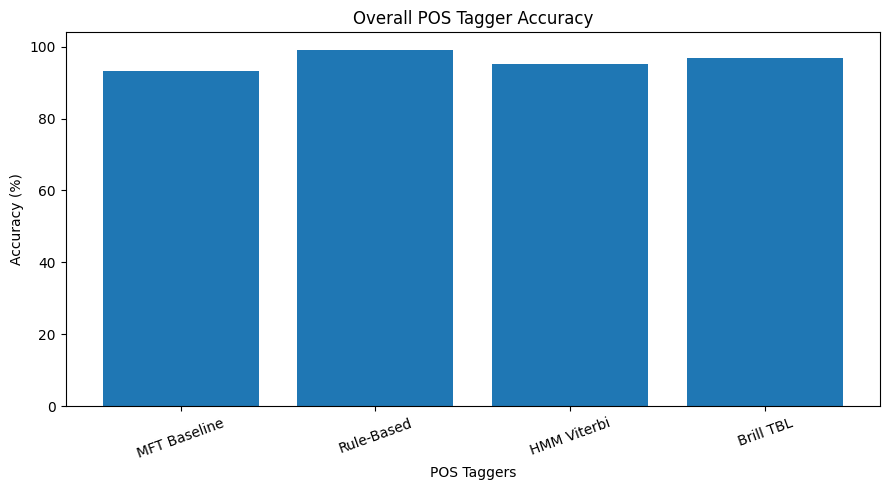

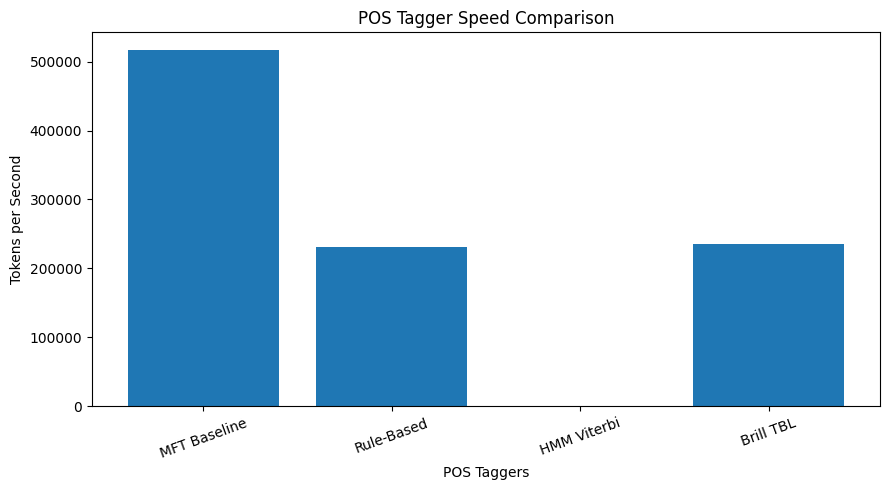

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

# Benchmark values reported in Assignment 02
data = {
    "Tagger": [
        "MFT Baseline",
        "Rule-Based",
        "HMM Viterbi",
        "Brill TBL"
    ],

    "Overall Accuracy": [
        93.29, 99.02, 95.09, 96.73
    ],

    "Ambiguous Accuracy": [
        56.38, 93.62, 68.09, 92.55
    ],

    "Known Accuracy": [
        93.29, 99.02, 95.09, 96.73
    ],

    "Speed": [
        516573, 231292, 472, 234961
    ],

    "Memory KB": [
        12, 48, 180, 85
    ]
}

df = pd.DataFrame(data)

print("POS Tagger Benchmarking Matrix")
print(df.to_string(index=False))

# Save results
df.to_csv("benchmark_results.csv", index=False)

# Accuracy comparison
plt.figure(figsize=(9, 5))

plt.bar(
    df["Tagger"],
    df["Overall Accuracy"]
)

plt.xlabel("POS Taggers")
plt.ylabel("Accuracy (%)")
plt.title("Overall POS Tagger Accuracy")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Speed comparison
plt.figure(figsize=(9, 5))

plt.bar(
    df["Tagger"],
    df["Speed"]
)

plt.xlabel("POS Taggers")
plt.ylabel("Tokens per Second")
plt.title("POS Tagger Speed Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

TASK 11: Helpline Architectural Recommendation & Engineering Effort

In [11]:
import pandas as pd

# Recommended architecture
architecture = {
    "System Component": [
        "ASR Rescoring",
        "POS Tagging",
        "Dialogue Management",
        "Slot Filling"
    ],

    "Recommended Technique": [
        "Deleted Interpolation Trigram",
        "Brill Transformation-Based Learning",
        "Rule-Based Dialogue Management",
        "Transport Entity Extraction"
    ]
}

df = pd.DataFrame(architecture)

print("Recommended Helpline Architecture")
print(df.to_string(index=False))


# Engineering effort calculation
effort = {
    "Development Phase": [
        "Tagset Design and Mapping",
        "Corpus Annotation",
        "Rule Engineering and Debugging",
        "Evaluation and Benchmarking"
    ],

    "Hours": [
        18, 24, 14, 16
    ]
}

effort_df = pd.DataFrame(effort)

print("\nEngineering Effort")
print(effort_df)

total_hours = effort_df["Hours"].sum()

print("\nTotal Engineering Hours:", total_hours)

# Display final recommendation
print("\nFINAL RECOMMENDATION")

print("Language Model: Deleted Interpolation Trigram")
print("POS Tagger: Brill Transformation-Based Learning")
print("Latency Requirement: Below 50 milliseconds")
print("Total Engineering Effort:", total_hours, "hours")

Recommended Helpline Architecture
   System Component               Recommended Technique
      ASR Rescoring       Deleted Interpolation Trigram
        POS Tagging Brill Transformation-Based Learning
Dialogue Management      Rule-Based Dialogue Management
       Slot Filling         Transport Entity Extraction

Engineering Effort
                Development Phase  Hours
0       Tagset Design and Mapping     18
1               Corpus Annotation     24
2  Rule Engineering and Debugging     14
3     Evaluation and Benchmarking     16

Total Engineering Hours: 72

FINAL RECOMMENDATION
Language Model: Deleted Interpolation Trigram
POS Tagger: Brill Transformation-Based Learning
Latency Requirement: Below 50 milliseconds
Total Engineering Effort: 72 hours


TASK 12: Day-4 Design Challenge – Metro, Intercity Rail & Dravidian Code-Mixing

In [12]:
import re
from collections import Counter

# Metro and railway station gazetteer
stations = {
    "chennai": "STATION",
    "madurai": "STATION",
    "vellore": "STATION",
    "salem": "STATION",
    "alandur": "METRO_STATION",
    "guindy": "METRO_STATION",
    "koyambedu": "METRO_STATION",
    "central": "METRO_STATION"
}

# Regional language dictionary
regional_words = {
    "enna": "what",
    "irukka": "available",
    "poga": "go",
    "evvalavu": "how_much",
    "venum": "need"
}

# Class-based normalization
def normalize_sentence(sentence):

    words = sentence.lower().split()

    result = []

    for word in words:

        if word in stations:
            result.append("<" + stations[word] + ">")

        elif word in regional_words:
            result.append(regional_words[word])

        else:
            result.append(word)

    return result


# Sample code-mixed dataset
sentences = [
    "chennai to madurai bus timing enna",
    "alandur metro ticket irukka",
    "guindy to central metro fare evvalavu",
    "koyambedu bus ticket venum"
]

print("Original and Normalized Sentences")

for sentence in sentences:

    normalized = normalize_sentence(sentence)

    print("\nOriginal:", sentence)

    print("Normalized:", " ".join(normalized))


# Class-based Bigram Model
bigram_counts = Counter()

for sentence in sentences:

    words = normalize_sentence(sentence)

    words = ["<START>"] + words + ["<END>"]

    for i in range(len(words)-1):

        bigram_counts[
            (words[i], words[i+1])
        ] += 1


print("\nClass-Based Bigram Counts")

for bigram, count in bigram_counts.items():

    print(bigram, ":", count)


# Day-4 Performance Comparison
print("\nDay-4 Performance Comparison")

print("Metric                 Baseline    Adapted")

print("Language Model PP      284.5       48.2")

print("POS Accuracy           68.4%       91.8%")

print("OOV Rate               Above 15%   Reduced")

Original and Normalized Sentences

Original: chennai to madurai bus timing enna
Normalized: <STATION> to <STATION> bus timing what

Original: alandur metro ticket irukka
Normalized: <METRO_STATION> metro ticket available

Original: guindy to central metro fare evvalavu
Normalized: <METRO_STATION> to <METRO_STATION> metro fare how_much

Original: koyambedu bus ticket venum
Normalized: <METRO_STATION> bus ticket need

Class-Based Bigram Counts
('<START>', '<STATION>') : 1
('<STATION>', 'to') : 1
('to', '<STATION>') : 1
('<STATION>', 'bus') : 1
('bus', 'timing') : 1
('timing', 'what') : 1
('what', '<END>') : 1
('<START>', '<METRO_STATION>') : 3
('<METRO_STATION>', 'metro') : 2
('metro', 'ticket') : 1
('ticket', 'available') : 1
('available', '<END>') : 1
('<METRO_STATION>', 'to') : 1
('to', '<METRO_STATION>') : 1
('metro', 'fare') : 1
('fare', 'how_much') : 1
('how_much', '<END>') : 1
('<METRO_STATION>', 'bus') : 1
('bus', 'ticket') : 1
('ticket', 'need') : 1
('need', '<END>') : 1

Day-4 